# Evaluate the different scan on the observations

In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib import cm, colors as mcolors


import numpy as np
import astropy.units as u

from astropy.coordinates import (
    SkyCoord,
    AltAz,
    EarthLocation,
)
from astropy.time import Time


# import imageio # to collect frames and write them into an animated file.
import os
# from PIL import Image
# import io

import scienceplots
plt.style.use(['science', 'no-latex'])

from typing import Optional

from pybaselines import Baseline, utils 
from scipy.signal import find_peaks, peak_widths
from scipy.stats import skew, kurtosis, gaussian_kde
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

#from concurrent.futures import ProcessPoolExecutor


In [2]:

# Compute VM^2R for single-dish data
def variance_to_median_square_ratio_single_dish(
    obj,
    time_dim: str = "time",
    freq_dim: str = "freq",
    pol_dim: str | None = None,
    eps: float = 1e-12,
) -> xr.Dataset:
    """
    Compute the variance-to-median-square ratio (VM^2R) over time for a
    single-dish dataset.

    Parameters
    ----------
    obj : xr.DataArray or xr.Dataset
        Input dynamic spectrum. If a Dataset is provided, the first data variable
        is used. Expected dimensions include time and frequency, and optionally
        polarization.
    time_dim : str, optional
        Name of the time dimension. Default is "time".
    freq_dim : str, optional
        Name of the frequency dimension. Default is "freq".
    pol_dim : str or None, optional
        Name of the polarization/feed dimension, if present. If None, the
        function assumes no extra per-feed/pol dimension. Default is None.
    eps : float, optional
        Small positive floor used to avoid division by zero. Default is 1e-12.

    Returns
    -------
    xr.Dataset
        Contains:
        - median: time-median per (freq[, pol])
        - variance: time-variance per (freq[, pol])
        - vm2r: variance / median^2 per (freq[, pol])
        - vm2r_by_freq: median VM^2R over polarization/feed (if pol_dim exists),
                        otherwise same as vm2r
        - vm2r_by_pol: median VM^2R over frequency (if pol_dim exists)
        - vm2r_global: global median VM^2R

    Notes
    -----
    VM^2R = Var(X) / Median(X)^2

    For single-dish total-power data this is useful for flagging non-stationary,
    bursty, or RFI-like behaviour in the time-frequency plane.
    """
    # Handle Dataset vs DataArray
    if isinstance(obj, xr.Dataset):
        var_name = list(obj.data_vars)[0]
        data_da = obj[var_name]
    else:
        data_da = obj

    # Check required dims
    required_dims = {time_dim, freq_dim}
    missing = required_dims - set(data_da.dims)
    if missing:
        raise ValueError(f"Input is missing required dimensions: {missing}")

    if pol_dim is not None and pol_dim not in data_da.dims:
        raise ValueError(f"pol_dim='{pol_dim}' not found in input dimensions {data_da.dims}")

    # Compute time statistics
    x = data_da.chunk({time_dim: -1})
    time_median = x.median(dim=time_dim, skipna=True).rename("median")
    time_variance = x.var(dim=time_dim, skipna=True).rename("variance")

    # VM^2R
    denom = time_median**2
    vm2r = (time_variance / denom).rename("vm2r")
    vm2r = vm2r.where(np.abs(time_median) > eps)

    out = {
        "median": time_median,
        "variance": time_variance,
        "vm2r": vm2r,
    }

    # 1D summaries
    if pol_dim is not None:
        vm2r_by_pol = (
            vm2r.chunk({freq_dim: -1})
            .median(dim=freq_dim, skipna=True)
            .rename("vm2r_by_pol")
        )
        vm2r_by_freq = (
            vm2r.chunk({pol_dim: -1})
            .median(dim=pol_dim, skipna=True)
            .rename("vm2r_by_freq")
        )
        out["vm2r_by_pol"] = vm2r_by_pol
        out["vm2r_by_freq"] = vm2r_by_freq
    else:
        out["vm2r_by_freq"] = vm2r.rename("vm2r_by_freq")

    # Global median
    vm2r_global = xr.DataArray(
        np.nanmedian(vm2r.compute().values),
        name="vm2r_global"
    )
    out["vm2r_global"] = vm2r_global

    return xr.Dataset(out)



# Compute VM^2R as a function of time for single-dish data
def variance_to_median_square_ratio_time(
    obj,
    time_dim: str = "time",
    freq_dim: str = "freq",
    pol_dim: str | None = None,
    eps: float = 1e-12,
) -> xr.Dataset:
    """
    Compute the Variance-to-Median-Square Ratio (VM^2R)
    as a function of time.

    VM^2R(t) = Var_f[X(f,t)] / Median_f[X(f,t)]^2

    Parameters
    ----------
    obj : xr.DataArray or xr.Dataset
        Dynamic spectrum containing time-frequency data.
    time_dim : str
        Name of the time dimension.
    freq_dim : str
        Name of the frequency dimension.
    pol_dim : str or None
        Optional polarization/feed dimension.
    eps : float
        Small threshold to avoid division by zero.

    Returns
    -------
    xr.Dataset
        Dataset containing:
        - median(time[, pol])
        - variance(time[, pol])
        - vm2r(time[, pol])
        - vm2r_by_time(time)
        - vm2r_global
    """

    # Handle Dataset vs DataArray
    if isinstance(obj, xr.Dataset):
        var_name = list(obj.data_vars)[0]
        data_da = obj[var_name]
    else:
        data_da = obj

    # Check required dimensions
    required_dims = {time_dim, freq_dim}
    missing = required_dims - set(data_da.dims)

    if missing:
        raise ValueError(f"Missing required dimensions: {missing}")

    if pol_dim is not None and pol_dim not in data_da.dims:
        raise ValueError(
            f"pol_dim='{pol_dim}' not found in dimensions {data_da.dims}"
        )

    # Chunk over frequency for efficient statistics
    x = data_da.chunk({freq_dim: -1})

    # Frequency statistics at each time sample
    freq_median = (
        x.median(dim=freq_dim, skipna=True)
        .rename("median")
    )

    freq_variance = (
        x.var(dim=freq_dim, skipna=True)
        .rename("variance")
    )

    # VM^2R(t)
    denom = freq_median**2

    vm2r = (
        freq_variance / denom
    ).rename("vm2r")

    # Avoid division by zero
    vm2r = vm2r.where(np.abs(freq_median) > eps)

    out = {
        "median": freq_median,
        "variance": freq_variance,
        "vm2r": vm2r,
    }

    # Collapse polarization if present
    if pol_dim is not None:
        vm2r_by_time = (
            vm2r
            .median(dim=pol_dim, skipna=True)
            .rename("vm2r_by_time")
        )
    else:
        vm2r_by_time = vm2r.rename("vm2r_by_time")

    out["vm2r_by_time"] = vm2r_by_time

    # Global statistic
    vm2r_global = xr.DataArray(
        np.nanmedian(vm2r.values),
        name="vm2r_global"
    )

    out["vm2r_global"] = vm2r_global

    return xr.Dataset(out)

# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-07-22T16_58_22.326155UTC_auMzw.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5

EDD_2023-08-09T19_46_45.289915UTC_viGdg.hdf5

In [3]:
# DATA
filename = "EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# # Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = False

In [4]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e9
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]                        # deg
        dec = f[f"{g}/dec"][30:]                      # deg       

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum),
             "integration_time": (("time"), integration_time)},
            coords={"time": time, "frequency": frequency, "ra": ra, "dec": dec}
        )

        datasets[g] = ds

In [5]:
# select a scan
scan = 'scan/001/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 163MB
Dimensions:           (time: 634, frequency: 63877, ra: 634, dec: 634)
Coordinates:
  * time              (time) float64 5kB 1.682e+09 1.682e+09 ... 1.682e+09
  * frequency         (frequency) float64 511kB 1.793 1.793 ... 3.498 3.498
  * ra                (ra) float64 5kB 83.89 83.89 83.9 ... 86.96 86.97 86.97
  * dec               (dec) float64 5kB -1.065 -1.067 -1.069 ... -2.786 -2.789
Data variables:
    spectrum          (time, frequency) float32 162MB 1.897e+11 ... 4.266e+09
    integration_time  (time) float64 5kB 0.1159 0.1159 0.1142 ... 0.115 0.1137

In [6]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]

frequency_ghz = data['frequency'].values 
time = data['time'].values
ra = data['ra'].values
dec = data['dec'].values




# Spectrum to dB
spectrum_db = 10*np.log10(spectrum**2)
mean_spectrum_db = np.mean(spectrum_db, axis=0)


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


In [7]:
results_freq = variance_to_median_square_ratio_time(xr.DataArray(spectrum, dims=['time', 'frequency']), time_dim='time', freq_dim='frequency')
results_freq

<xarray.Dataset> Size: 20kB
Dimensions:       (time: 634)
Dimensions without coordinates: time
Data variables:
    median        (time) float64 5kB dask.array<chunksize=(634,), meta=np.ndarray>
    variance      (time) float64 5kB dask.array<chunksize=(634,), meta=np.ndarray>
    vm2r          (time) float64 5kB dask.array<chunksize=(634,), meta=np.ndarray>
    vm2r_by_time  (time) float64 5kB dask.array<chunksize=(634,), meta=np.ndarray>
    vm2r_global   float64 8B 0.1386

Text(0.5, 0, 'Time [s]')

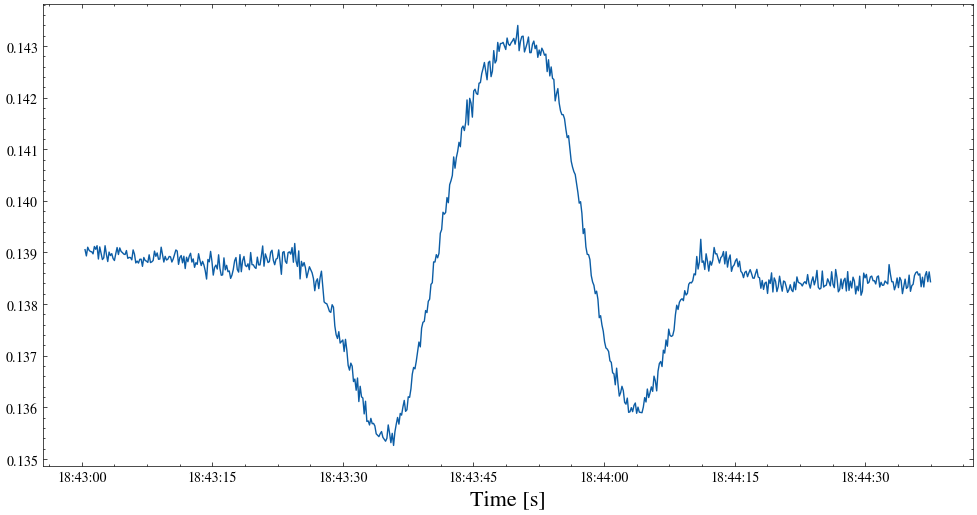

In [8]:
vm2r_freq = results_freq['vm2r_by_time'].values
plt.figure(figsize=(12, 6))
plt.plot(time_utc, vm2r_freq, label='VM²R by Time')
#plt.plot(vm2r_freq[0:150])
plt.xlabel("Time [s]", fontsize=16)

In [9]:


def compute_pointing_offset(
    azimuth,
    elevation,
    target_ra,
    target_dec,
    obstime,
    latitude,
    longitude,
    height=0.0,
    az_unit=u.deg,
    el_unit=u.deg,
    ra_unit=u.deg,
    dec_unit=u.deg,
):
    """
    Compute the angular separation between the telescope pointing
    direction (Az/El) and a target sky position (RA/Dec).

    Parameters
    ----------
    azimuth : float or array-like
        Telescope azimuth coordinates.

    elevation : float or array-like
        Telescope elevation (altitude) coordinates.

    target_ra : float
        Right Ascension of the target source.

    target_dec : float
        Declination of the target source.

    obstime : str, astropy.time.Time, or array-like
        Observation time(s). Can be:
            - ISO string
            - Astropy Time object
            - list/array of times

    latitude : float
        Observatory latitude.

    longitude : float
        Observatory longitude.

    height : float, optional
        Observatory height above sea level in meters.
        Default is 0.

    az_unit : astropy.units.Unit
        Unit of azimuth values.
        Default is degrees.

    el_unit : astropy.units.Unit
        Unit of elevation values.
        Default is degrees.

    ra_unit : astropy.units.Unit
        Unit of Right Ascension.
        Default is degrees.

    dec_unit : astropy.units.Unit
        Unit of Declination.
        Default is degrees.

    Returns
    -------
    separation : astropy.coordinates.Angle
        Angular separation between telescope pointing and target.

    separation_deg : ndarray
        Angular separation in degrees.

    Notes
    -----
    This function works by:

    1. Defining the observatory location.
    2. Constructing the telescope pointing direction in the AltAz frame.
    3. Constructing the target source in the ICRS frame.
    4. Transforming the target into the local AltAz frame.
    5. Computing the great-circle angular separation.

    The angular separation is given by:

    """

        # ------------------------------------------------------------------
    # Observatory location
    # ------------------------------------------------------------------
    location = EarthLocation(
        lat=latitude * u.deg,
        lon=longitude * u.deg,
        height=height * u.m,
    )

    # ------------------------------------------------------------------
    # Observation time
    # ------------------------------------------------------------------
    obstime = Time(obstime)

    # ------------------------------------------------------------------
    # Telescope pointing coordinates (AltAz frame)
    # ------------------------------------------------------------------
    telescope_pointing = SkyCoord(
        az=np.asarray(azimuth) * az_unit,
        alt=np.asarray(elevation) * el_unit,
        frame=AltAz(
            obstime=obstime,
            location=location,
        ),
    )

    # ------------------------------------------------------------------
    # Target source coordinates (ICRS frame)
    # ------------------------------------------------------------------
    target_icrs = SkyCoord(
        ra=target_ra * ra_unit,
        dec=target_dec * dec_unit,
        frame="icrs",
    )

    # ------------------------------------------------------------------
    # Transform target to local AltAz frame
    # ------------------------------------------------------------------
    target_altaz = target_icrs.transform_to(
        AltAz(
            obstime=obstime,
            location=location,
        )
    )

    # ------------------------------------------------------------------
    # Angular separation
    # ------------------------------------------------------------------
    separation = telescope_pointing.separation(target_altaz)

    return separation, separation.deg

In [10]:
# Example:
sep_angle, sep_deg = compute_pointing_offset(
    azimuth=180.0,
    elevation=45.0,
    target_ra=83.6331,      # Crab Nebula RA
    target_dec=22.0145,     # Crab Nebula DEC
    obstime="2026-04-18T12:00:00",
    latitude=-30.7215,      # MeerKAT latitude
    longitude=21.4110,      # MeerKAT longitude
    height=1050,            # meters
)

print(sep_angle)
print(sep_deg)

100d17m12.50255647s
100.28680626568611


In [11]:
#for observation done on 2023-04-18T18:40:20.581801UTC, the pointing offset to the Crab Nebula is approximately 0.5 degrees.
ra_taurus = 83.6331
dec_taurus = +22.0145

#for observation done on 2023-04-18T18:40:20.581801UTC, the pointing offset to the Crab Nebula is approximately 0.5 degrees.
ra_spass= 85.4083
dec_spass= -1.9158

In [12]:
angular_separation = []

for i in range(len(time_utc)):
    
    # ------------------------------------------------------------------
    # Telescope pointing coordinates (AltAz frame)
    # ------------------------------------------------------------------
    telescope_pointing = SkyCoord(
        ra=ra[i] * u.deg,
        dec=dec[i] * u.deg,
        frame="icrs",
    )

    # ------------------------------------------------------------------
    # Target source coordinates (ICRS frame)
    # ------------------------------------------------------------------
    target_icrs = SkyCoord(
        ra=ra_spass * u.deg,
        dec=dec_spass * u.deg,
        frame="icrs",
    )


    # ------------------------------------------------------------------
    # Angular separation
    # ------------------------------------------------------------------
    separation = telescope_pointing.separation(target_icrs)
    angular_separation.append(separation.value)

Text(0.5, 0, 'Time [UTC]')

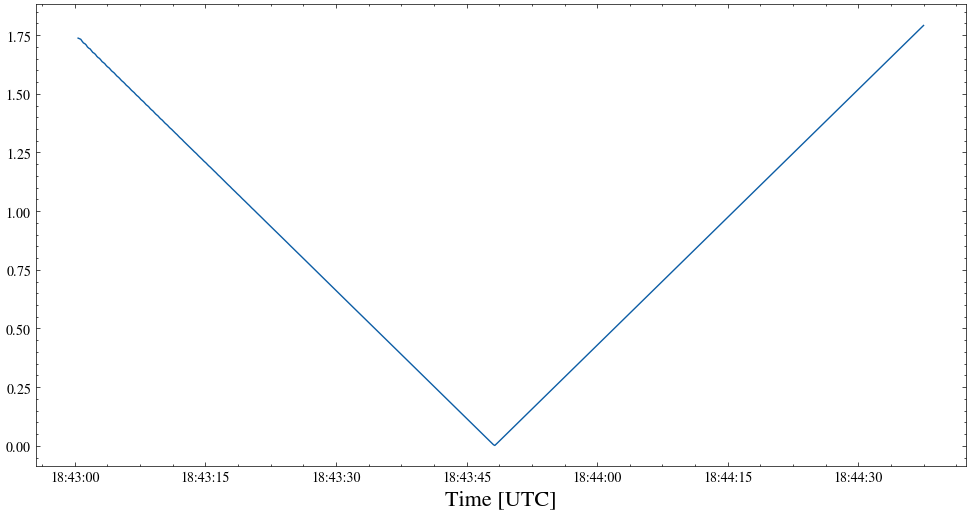

In [13]:
plt.figure(figsize=(12, 6))
plt.plot(time_utc, angular_separation)
plt.xlabel("Time [UTC]", fontsize=16)

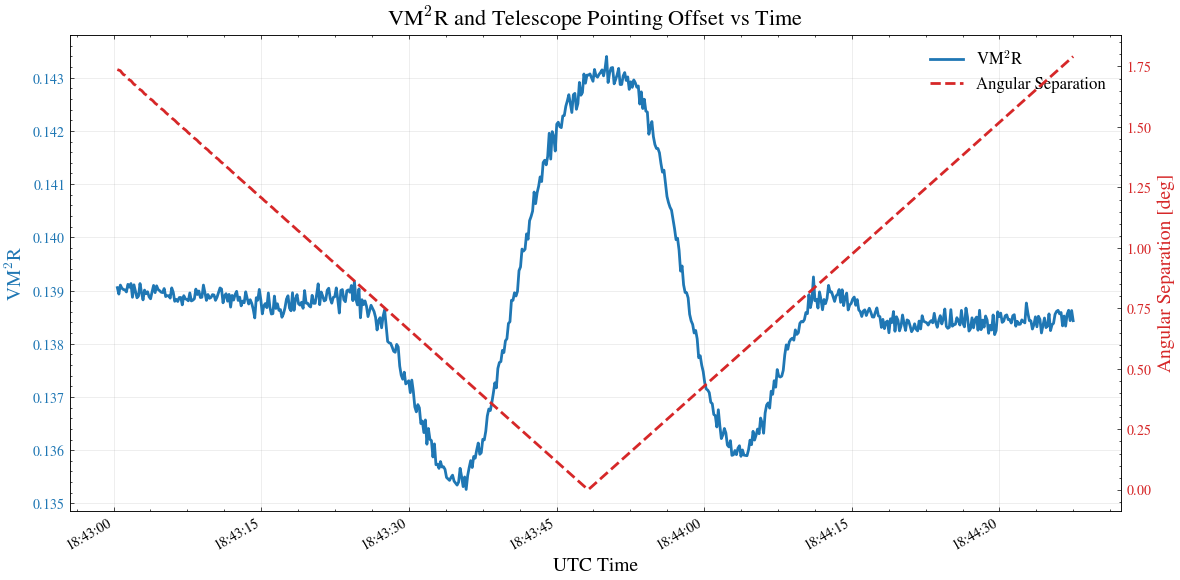

In [14]:

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(12, 6))

# ------------------------------------------------------------
# Left axis : VM²R
# ------------------------------------------------------------
line1 = ax1.plot(
    time_utc,
    vm2r_freq,
    color='tab:blue',
    linewidth=2,
    label='VM$^2$R'
)

ax1.set_xlabel("UTC Time", fontsize=14)

ax1.set_ylabel(
    "VM$^2$R",
    color='tab:blue',
    fontsize=14
)

ax1.tick_params(
    axis='y',
    labelcolor='tab:blue'
)

# ------------------------------------------------------------
# Right axis : Angular separation
# ------------------------------------------------------------
ax2 = ax1.twinx()

line2 = ax2.plot(
    time_utc,
    angular_separation,
    color='tab:red',
    linewidth=2,
    linestyle='--',
    label='Angular Separation'
)

ax2.set_ylabel(
    "Angular Separation [deg]",
    color='tab:red',
    fontsize=14
)

ax2.tick_params(
    axis='y',
    labelcolor='tab:red'
)

# ------------------------------------------------------------
# Time formatting
# ------------------------------------------------------------
ax1.xaxis.set_major_formatter(
    mdates.DateFormatter('%H:%M:%S')
)

fig.autofmt_xdate()

# ------------------------------------------------------------
# Combined legend
# ------------------------------------------------------------
lines = line1 + line2
labels = [l.get_label() for l in lines]

ax1.legend(
    lines,
    labels,
    loc='upper right',
    fontsize=12
)

# ------------------------------------------------------------
# Grid and layout
# ------------------------------------------------------------
ax1.grid(True, alpha=0.3)

plt.title(
    "VM$^2$R and Telescope Pointing Offset vs Time",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [15]:
spectrum_db.shape

(634, 63877)

Text(0, 0.5, 'Mean Spectrum [dB]')

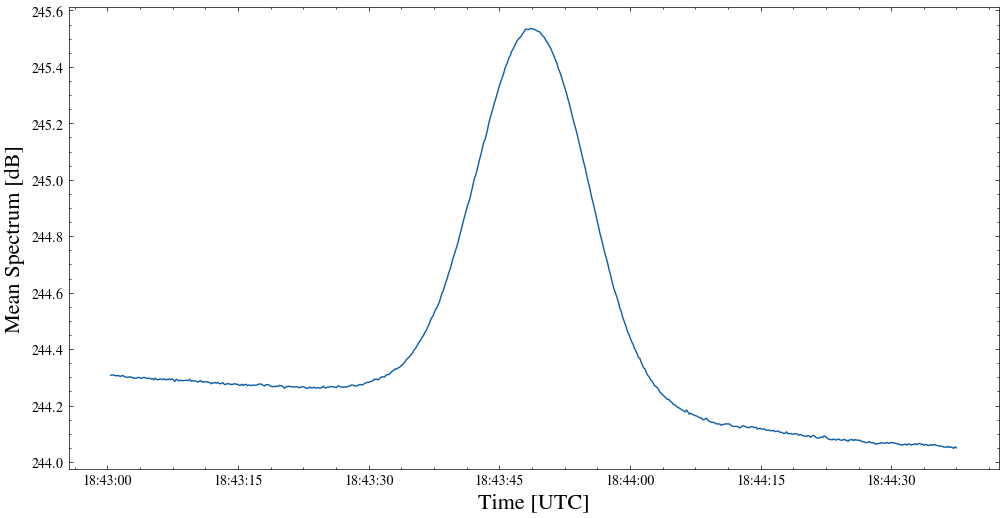

In [16]:
spectrum_db_fre = np.mean(spectrum_db, axis=1)


plt.figure(figsize=(12, 6))
plt.plot(time_utc, spectrum_db_fre)
plt.xlabel("Time [UTC]", fontsize=16)
plt.ylabel("Mean Spectrum [dB]", fontsize=16)